In [1]:
import numpy as np
from scipy.optimize import curve_fit

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator, NullFormatter

import delayscan.kineticmodels as km



In [2]:
# Load default mpl style
plt.style.use("assets/TRPES.mplstyle")

#Other standard figure widths
fwid = 6.26894
ACSwid = 3.33
thesisWid = 14/2.54

#Default mpl colour tablet
colors = list(mcolors.TABLEAU_COLORS)

#Extra colours
violet = '#5D3FD3'
red = '#D62828'

blue ='#3A86FF'
green='#6A994E'

In [3]:
CROSS_CORRELATION = 0.320 #cross-correlation with 250 & 267
SIGMA = CROSS_CORRELATION / 2.355 



In [4]:
# Load data to fit
loaddata = np.loadtxt("data/out/subtractedspectra.csv",delimiter=',')

energies_rebinned = loaddata[0,1:]
delays_t0 = loaddata[1:,0]
subtracted_rebinned = loaddata [1:,1:]

In [5]:
# Must process data to fit only the relevant data
# Must also flatten the data so that we can fit it with scipy's curve_fit 

In [6]:
# Select data below 2.2 eV as above it is ~0
# and it would skew the fits with noise
mask = energies_rebinned<2.2
traces = subtracted_rebinned[:,mask]

# Normalise traces by max counts so that we get nice numbers
traces /= np.amax(traces)


In [7]:
#Flatten delays
#Choose delays
delays = delays_t0
# Tile delays
flat_delays = np.tile(delays,(traces.shape[1]))
#Flatten traces
flat_traces = traces.T.flatten() 
flat_traces.shape,flat_delays.shape

((3290,), (3290,))

### EAS model

In [19]:
model = km.EAS_model(0,SIGMA,*traces.shape)

In [20]:
p0 = [1,3.5]+[x for n in range(70) for x in (2*n, n)]

params,pcov = curve_fit(model.global_fit,flat_delays,flat_traces,
                        p0 = p0,bounds=(-np.inf,np.inf),)
perr = np.sqrt(np.diag(pcov))
params[:2],params[2:]

(array([0.54994654, 2.84328419]),
 array([ 1.30077726e-02, -4.80057398e-04,  1.27706499e-02, -1.95941299e-04,
         1.55432944e-02,  1.63312701e-03,  1.86227256e-02, -3.43872981e-04,
         1.72193871e-02,  2.49457413e-03,  2.35312245e-02,  3.37104939e-03,
         3.14226361e-02,  4.01338316e-03,  3.76344802e-02,  2.33211424e-03,
         5.07517505e-02,  5.19813585e-03,  6.24363970e-02,  1.32972181e-02,
         8.40183495e-02,  1.54147168e-02,  1.05730985e-01,  2.21093334e-02,
         1.30703880e-01,  2.62641975e-02,  1.69424804e-01,  4.43349046e-02,
         2.09555579e-01,  5.76405693e-02,  2.46025381e-01,  7.43951235e-02,
         2.85065590e-01,  9.50186248e-02,  3.31403721e-01,  1.29497011e-01,
         3.80943940e-01,  1.57275010e-01,  4.29541617e-01,  1.83888848e-01,
         4.95696514e-01,  2.02600885e-01,  5.39288784e-01,  2.56129636e-01,
         5.77695377e-01,  3.07130557e-01,  6.39783596e-01,  3.59593804e-01,
         7.06676564e-01,  3.78333705e-01,  7.54765063e

0.5499465379378774 2.843284193244183


(-1.0, 5.0)

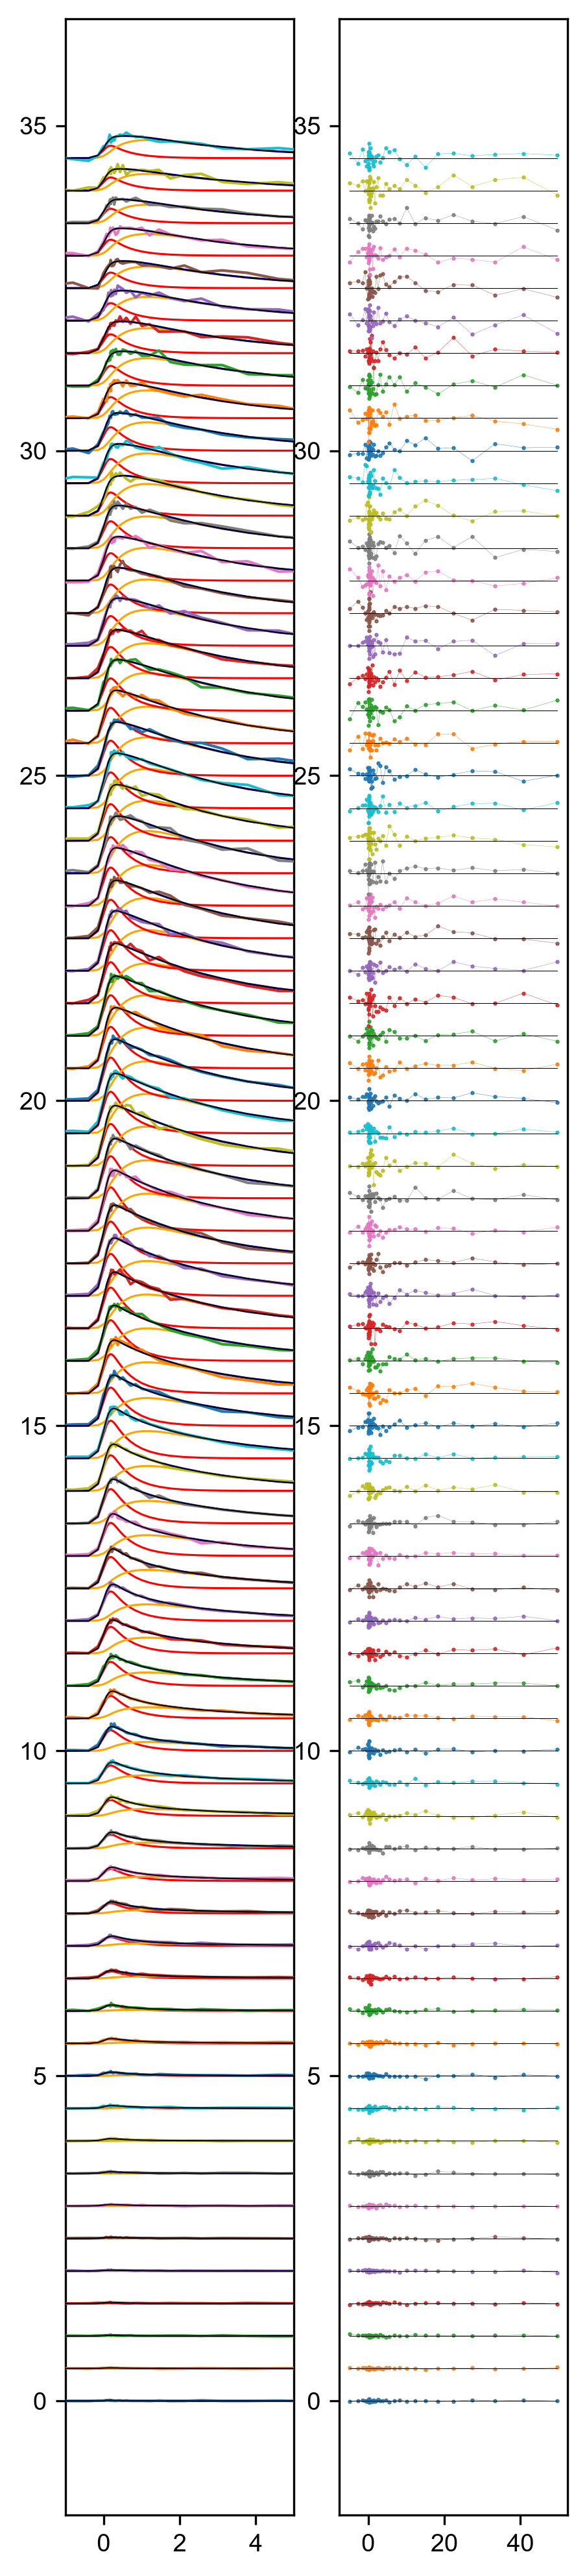

In [21]:
fig, (ax0,ax1) = plt.subplots(1,2)
# params=p0
tau1,tau2, amplitudes = params[0],params[1],params[2:]
tau1_err,tau2_err, amplitudes_err = perr[0],perr[1],perr[2:]
print(tau1,tau2)
sigma = 0.320 / 2.355 #cross-correlation with 250 & 267
t0 = 0

for n in range(70):
    
    ax0.plot(delays,traces[:,n]+.5*n,zorder=20)
    
    trace = model.kinetic_model(delays,amplitudes[2*n],amplitudes[2*n+1],tau1,tau2)
    ax0.plot(delays,trace+.5*n,'k',zorder=30,lw=.5)
    
    
    trace =  model.A_model(delays,amplitudes[2*n],tau1,sigma)
    ax0.plot(delays,trace+.5*n,'r',lw=.75)
    
    trace =  model.B_model(delays,amplitudes[2*n+1],tau1,tau2,sigma)
    ax0.plot(delays,trace+.5*n,'orange',lw=.75)
    ax0.plot(delays,model.A_model(delays,amplitudes[2*n],tau1,sigma)+trace+.5*n,'b',lw=.75)

    # Residuals
    trace = model.kinetic_model(delays,amplitudes[2*n],amplitudes[2*n+1],tau1,tau2)
    ax1.plot(delays,3*(traces[:,n]-trace)+.5*n,'o-',zorder=20,ms=.5,lw=.1)
    ax1.plot(delays,delays*0+.5*n,'k',zorder=30,lw=.25)
    
ax1.set_ylim(ax0.get_ylim())
plt.gcf().set_size_inches(ACSwid,ACSwid*5)

ax0.set_xlim(-1,5)

Text(0, 0.5, 'Photoelectron signal / a.u.')

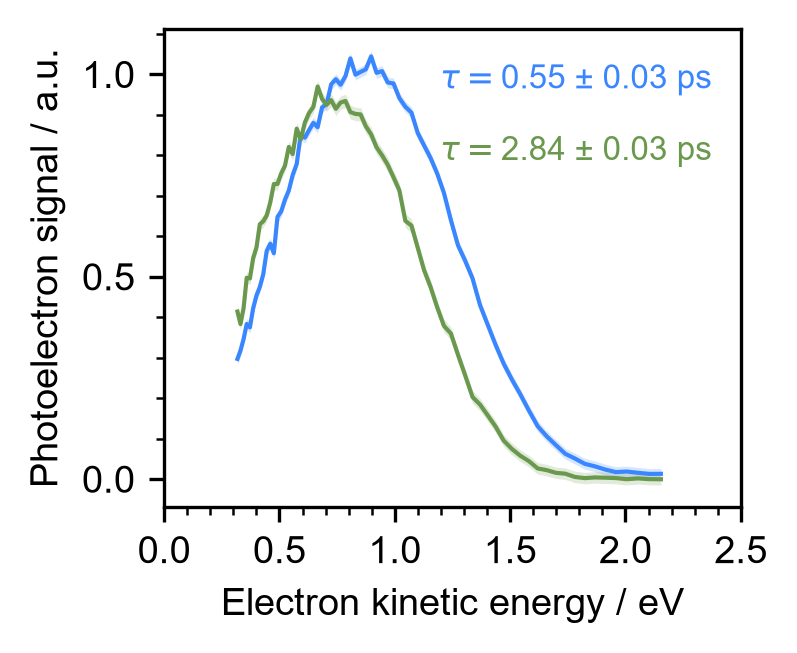

In [22]:
fig,ax = plt.subplots(1)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(300)
fig.set_size_inches(thesisWid*.45,thesisWid/2*0.75)

A1s = amplitudes[0::2]
A2s = amplitudes[1::2]
A1s_err = amplitudes_err[0::2]
A2s_err = amplitudes_err[1::2]
energies = energies_rebinned[mask]

ax.plot(energies,A1s,'-',c=blue,ms=1,label=f"$\\tau = ${tau1:.2f}$\\pm${tau1_err:.2f} ps")
ax.plot(energies,A2s,'-',c=green,ms=1,label=f"$\\tau = ${tau2:.2f}$\\pm${tau2_err:.2f} ps")

ax.fill_between(energies,A1s-A1s_err,A1s+A1s_err,alpha=.2,color=blue,lw=0)
ax.fill_between(energies,A2s-A2s_err,A2s+A2s_err,alpha=.2,color=green,lw=0)

ax.text(.95,.8,f"$\\tau =${tau1:.2f} ± {tau1_err:.2f} ps\n",ha='right',c=blue,fontsize=8,transform=ax.transAxes)
ax.text(.95,.65,f"$\\tau =${tau2:.2f} ± {tau2_err:.2f} ps\n",ha='right',c=green,fontsize=8,transform=ax.transAxes)

# ax.legend(frameon=False, title='EAS',title_fontsize=8)
ax = plt.gca()
ax.set_xlim(0,2.5)
# ax.set_ylim(0,1.2)
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.yaxis.set_major_locator(MultipleLocator(.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))
    
ax.set_xlabel("Electron kinetic energy / eV",)
ax.set_ylabel("Photoelectron signal / a.u.")


### DAS model

In [23]:
model = km.DAS_model(0,SIGMA,*traces.shape)

In [24]:
p0 = [1,3.5]+[x for n in range(70) for x in (2*n, n)]

params,pcov = curve_fit(model.global_fit,flat_delays,flat_traces,
                        p0 = p0,bounds=(-np.inf,np.inf),)
perr = np.sqrt(np.diag(pcov))
params[:2],params[2:]

(array([0.54995531, 2.84328499]),
 array([ 1.36027290e-02, -5.95114319e-04,  1.30135408e-02, -2.42969810e-04,
         1.35183610e-02,  2.02479257e-03,  1.90487901e-02, -4.26269976e-04,
         1.41265536e-02,  3.09274140e-03,  1.93518104e-02,  4.17932801e-03,
         2.64468667e-02,  4.97565339e-03,  3.47429441e-02,  2.89129322e-03,
         4.43072338e-02,  6.44436084e-03,  4.59503040e-02,  1.64857944e-02,
         6.49068785e-02,  1.91110390e-02,  7.83194355e-02,  2.74110178e-02,
         9.81413577e-02,  3.25619932e-02,  1.14458081e-01,  5.49660692e-02,
         1.38092196e-01,  7.14624994e-02,  1.53790471e-01,  9.22342839e-02,
         1.67261236e-01,  1.17803498e-01,  1.70853762e-01,  1.60549402e-01,
         1.85954171e-01,  1.94988888e-01,  2.01556215e-01,  2.27984549e-01,
         2.44512414e-01,  2.51183255e-01,  2.21739497e-01,  3.17548488e-01,
         1.96915106e-01,  3.80779611e-01,  1.93959580e-01,  4.45823485e-01,
         2.37618570e-01,  4.69057160e-01,  2.28881288e

0.5499553135357947 2.8432849945022065


(-1.0, 5.0)

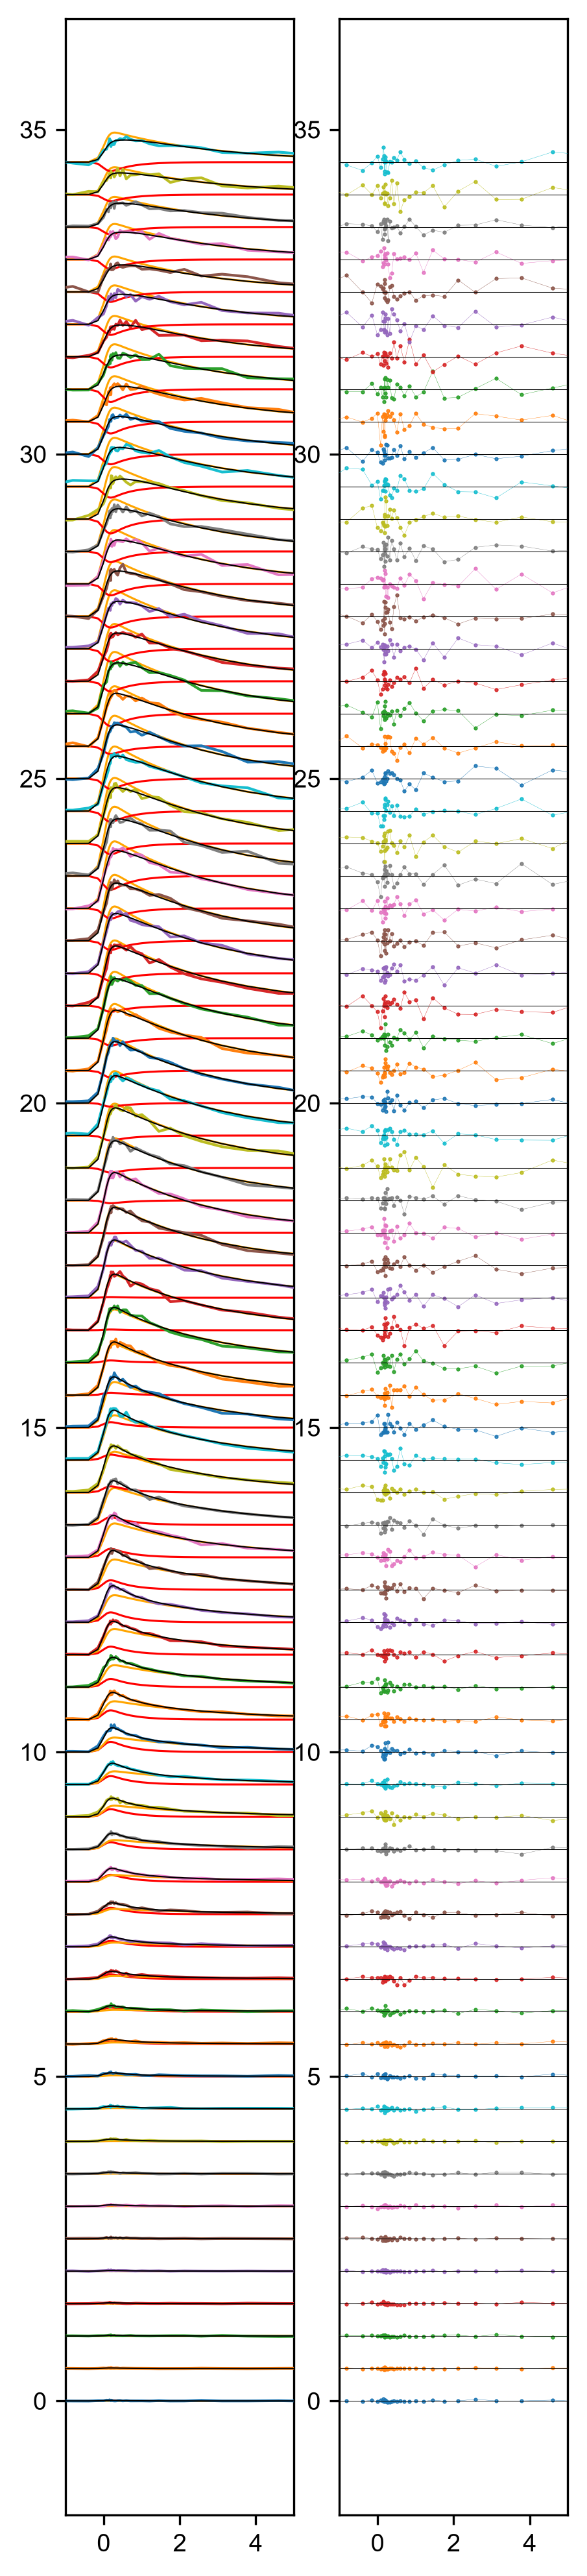

In [28]:
fig, (ax0,ax1) = plt.subplots(1,2)
# params=p0
tau1,tau2, amplitudes = params[0],params[1],params[2:]
tau1_err,tau2_err, amplitudes_err = perr[0],perr[1],perr[2:]
print(tau1,tau2)
sigma = 0.320 / 2.355 #cross-correlation with 250 & 267
t0 = 0

for n in range(70):
    
    ax0.plot(delays,traces[:,n]+.5*n,zorder=20)
    
    trace = model.kinetic_model(delays,amplitudes[2*n],amplitudes[2*n+1],tau1,tau2)
    ax0.plot(delays,trace+.5*n,'k',zorder=30,lw=.5)
    
    
    trace =  amplitudes[2*n]*km._monoexp(delays,1/tau1,sigma)
    ax0.plot(delays,trace+.5*n,'r',lw=.75)
    
    trace =  amplitudes[2*n+1]*km._monoexp(delays,1/tau2,sigma)
    ax0.plot(delays,trace+.5*n,'orange',lw=.75)

    # Residuals
    trace = model.kinetic_model(delays,amplitudes[2*n],amplitudes[2*n+1],tau1,tau2)
    ax1.plot(delays,3*(traces[:,n]-trace)+.5*n,'o-',zorder=20,ms=.5,lw=.1)
    ax1.plot(delays,delays*0+.5*n,'k',zorder=30,lw=.25)
    
ax1.set_ylim(ax0.get_ylim())
plt.gcf().set_size_inches(ACSwid,ACSwid*5)

ax0.set_xlim(-1,5)
ax1.set_xlim(-1,5)

Text(0, 0.5, 'Photoelectron signal / a.u.')

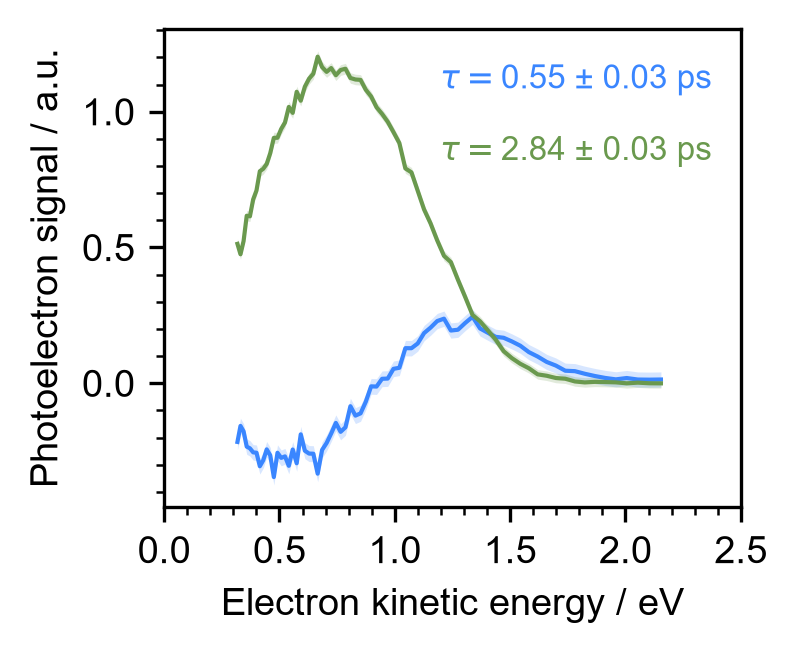

In [ ]:
fig,ax = plt.subplots(1)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(300)
fig.set_size_inches(thesisWid*.45,thesisWid/2*0.75)

A1s = amplitudes[0::2]
A2s = amplitudes[1::2]
A1s_err = amplitudes_err[0::2]
A2s_err = amplitudes_err[1::2]
energies = energies_rebinned[mask]

ax.plot(energies,A1s,'-',c=blue,ms=1,label=f"$\\tau = ${tau1:.2f}$\\pm${tau1_err:.2f} ps")
ax.plot(energies,A2s,'-',c=green,ms=1,label=f"$\\tau = ${tau2:.2f}$\\pm${tau2_err:.2f} ps")

ax.fill_between(energies,A1s-A1s_err,A1s+A1s_err,alpha=.2,color=blue,lw=0)
ax.fill_between(energies,A2s-A2s_err,A2s+A2s_err,alpha=.2,color=green,lw=0)

ax.text(.95,.8,f"$\\tau =${tau1:.2f} ± {tau1_err:.2f} ps\n",ha='right',c=blue,fontsize=8,transform=ax.transAxes)
ax.text(.95,.65,f"$\\tau =${tau2:.2f} ± {tau2_err:.2f} ps\n",ha='right',c=green,fontsize=8,transform=ax.transAxes)

# ax.legend(frameon=False, title='EAS',title_fontsize=8)
ax = plt.gca()
ax.set_xlim(0,2.5)
# ax.set_ylim(0,1.2)
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.yaxis.set_major_locator(MultipleLocator(.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))
    
ax.set_xlabel("Electron kinetic energy / eV",)
ax.set_ylabel("Photoelectron signal / a.u.")
